# Gabarito — Exercício Q-Learning vs. SARSA
### Aprendizado por Reforço | MBA em Ciência de Dados e IA

---

> **Este é o gabarito** do notebook `exercicio_qlearning_sarsa.ipynb` (slides 110 e 111): os `# TODO` estão preenchidos e as perguntas de reflexão, respondidas com base nos resultados abaixo.

## Contexto

Você já aprendeu os fundamentos do Q-Learning e do SARSA. Ambos os algoritmos usam uma **Q-table** e a estratégia **ε-greedy**, mas diferem em **como atualizam** essa tabela:

| | Q-Learning | SARSA |
|---|---|---|
| Tipo | Off-policy | On-policy |
| Atualização usa... | `max Q(s', a')` — a **melhor** ação possível | `Q(s', a')` — a ação **de fato** escolhida |
| Comportamento | Otimista / mais agressivo | Conservador / mais seguro |

### Equações de atualização

**Q-Learning (off-policy):**
$$Q(s,a) \leftarrow Q(s,a) + \alpha \Big[ r + \gamma \cdot \underbrace{\max_{a'} Q(s', a')}_{\text{melhor ação possível}} - Q(s,a) \Big]$$

**SARSA (on-policy):**
$$Q(s,a) \leftarrow Q(s,a) + \alpha \Big[ r + \gamma \cdot \underbrace{Q(s', a')}_{\text{ação real tomada}} - Q(s,a) \Big]$$

---

> ⏱️ **~30 min.** Os Exercícios 1 a 4 são o núcleo; o 5 é opcional (se sobrar tempo ou em casa).

---

## Ambiente — O Penhasco (*Cliff Walking*)

Este é o ambiente clássico de **Sutton & Barto (2018)** — o exemplo mais usado para demonstrar a diferença entre os dois algoritmos (slides 108 e 109). Usamos uma versão 4×9 do grid original 4×12.

```
  col →  0    1    2    3    4    5    6    7    8
      ┌─────────────────────────────────────────────┐
      │  ·    ·    ·    ·    ·    ·    ·    ·    ·  │  ← Linha 0 (topo)
      │  ·    ·    ·    ·    ·    ·    ·    ·    ·  │  ← Linha 1
      │  ·    ·    ·    ·    ·    ·    ·    ·    ·  │  ← Linha 2
      │  S    ☠    ☠    ☠    ☠    ☠    ☠    ☠    G  │  ← Linha 3 (base)
      └─────────────────────────────────────────────┘
```

- **S** = Início (linha 3, coluna 0)
- **G** = Objetivo (linha 3, coluna 8)
- **☠** = Penhasco — recompensa **-100** e retorna ao início
- **·** = Célula livre — recompensa **-1** por passo

### Por que este ambiente é perfeito para comparar os dois algoritmos?

Existe um caminho **curto mas arriscado** (pela borda do penhasco) e caminhos **mais longos e seguros** (afastados da borda).  
O Q-Learning tende a aprender o caminho curto (otimista).  
O SARSA tende a aprender o caminho seguro (conservador).

---

## Objetivos do Exercício

1. Implementar a **equação de atualização** do Q-Learning
2. Implementar a **equação de atualização** do SARSA
3. Comparar o comportamento e desempenho dos dois algoritmos
4. Interpretar os resultados e responder às perguntas de reflexão

---
## Célula 1 — Importações e Configuração

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import random

# Reprodutibilidade
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("Bibliotecas carregadas com sucesso!")

Bibliotecas carregadas com sucesso!


---
## Célula 2 — Definição do Ambiente

> **Leia com atenção.** Esta célula define o ambiente completo. Você não precisa modificá-la.

In [2]:
# ─── Dimensões do grid ───────────────────────────────────────────────────────
ROWS = 4
COLS = 9

# ─── Posições especiais ───────────────────────────────────────────────────────
START = (3, 0)   # Canto inferior esquerdo
GOAL  = (3, 8)   # Canto inferior direito

# Penhasco: todas as células da base entre o início e o objetivo
CLIFF = [(3, c) for c in range(1, 8)]

# ─── Recompensas ──────────────────────────────────────────────────────────────
R_STEP  = -1    # Penalidade por cada passo (incentiva caminhos curtos)
R_CLIFF = -100  # Cair no penhasco — retorna ao início
R_GOAL  = 0     # Recompensa ao chegar (a penalidade de passo já está inclusa)

# ─── Ações ───────────────────────────────────────────────────────────────────
ACTIONS = [0, 1, 2, 3]
ACTION_NAMES  = {0: 'Cima', 1: 'Baixo', 2: 'Esquerda', 3: 'Direita'}
ACTION_ARROWS = {0: '↑',   1: '↓',    2: '←',         3: '→'}
ACTION_DELTAS = {0: (-1,0), 1: (1,0),  2: (0,-1),       3: (0,1)}


# ─── Função de transição do ambiente ─────────────────────────────────────────
def step(state, action):
    """
    Executa uma ação no ambiente.

    Parâmetros:
        state  : tupla (row, col) — estado atual
        action : int  0=Cima, 1=Baixo, 2=Esquerda, 3=Direita

    Retorna:
        next_state : tupla (row, col)
        reward     : float
        done       : bool — True se o episódio terminou
    """
    r, c = state
    dr, dc = ACTION_DELTAS[action]
    nr = np.clip(r + dr, 0, ROWS - 1)   # não sai pelos limites verticais
    nc = np.clip(c + dc, 0, COLS - 1)   # não sai pelos limites horizontais

    next_state = (nr, nc)

    # ── Chegou ao objetivo ──
    if next_state == GOAL:
        return GOAL, R_GOAL, True

    # ── Caiu no penhasco ──
    if next_state in CLIFF:
        return START, R_CLIFF, False   # reinicia episódio (mas não termina!)

    # ── Passo normal ──
    return next_state, R_STEP, False


# ─── Política ε-greedy ────────────────────────────────────────────────────────
def choose_action(state, Q, epsilon):
    """
    Seleciona uma ação usando a estratégia ε-greedy.
      - Com probabilidade ε   → ação aleatória  (exploração)
      - Com probabilidade 1-ε → argmax Q(s, ·)  (explotação)
    """
    if random.random() < epsilon:
        return random.choice(ACTIONS)
    r, c = state
    return int(np.argmax(Q[r, c]))


print(f"Ambiente configurado: grid {ROWS}×{COLS}")
print(f"  Início   : {START}")
print(f"  Objetivo : {GOAL}")
print(f"  Penhasco : {len(CLIFF)} células")
print()
print("Teste rápido a partir do estado inicial:")
for a in ACTIONS:
    ns, r, d = step(START, a)
    print(f"  {ACTION_ARROWS[a]} {ACTION_NAMES[a]:9s} → {ns}  recompensa={r:+4d}  fim={d}")

Ambiente configurado: grid 4×9
  Início   : (3, 0)
  Objetivo : (3, 8)
  Penhasco : 7 células

Teste rápido a partir do estado inicial:
  ↑ Cima      → (np.int64(2), np.int64(0))  recompensa=  -1  fim=False
  ↓ Baixo     → (np.int64(3), np.int64(0))  recompensa=  -1  fim=False
  ← Esquerda  → (np.int64(3), np.int64(0))  recompensa=  -1  fim=False
  → Direita   → (3, 0)  recompensa=-100  fim=False


---
## Célula 3 — Visualização do Ambiente

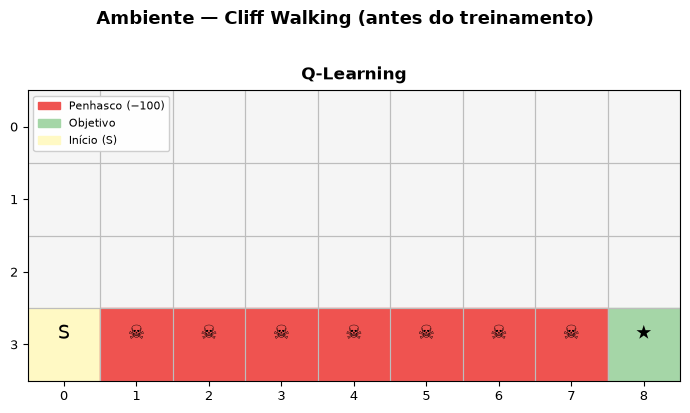

In [3]:
def plot_env(Q_ql=None, Q_sarsa=None, path_ql=None, path_sarsa=None, title="Cliff Walking"):
    """
    Visualiza o ambiente, e opcionalmente a política aprendida e o caminho percorrido.
    Aceita até dois agentes lado a lado: Q-Learning (esq.) e SARSA (dir.).
    """
    n_plots = 1 + (Q_sarsa is not None)
    fig, axes = plt.subplots(1, n_plots, figsize=(7 * n_plots, 4))
    if n_plots == 1:
        axes = [axes]

    configs = []
    if Q_ql is not None or n_plots == 1:
        configs.append((Q_ql, path_ql, 'Q-Learning'))
    if Q_sarsa is not None:
        configs.append((Q_sarsa, path_sarsa, 'SARSA'))
    if not configs:
        configs = [(None, None, 'Ambiente')]

    COR_LIVRE    = '#F5F5F5'
    COR_PENHASCO = '#EF5350'
    COR_INICIO   = '#FFF9C4'
    COR_GOAL     = '#A5D6A7'
    COR_CAMINHO  = {'Q-Learning': '#1565C0', 'SARSA': '#6A1B9A'}

    for ax, (Q, path, label) in zip(axes, configs):
        for r in range(ROWS):
            for c in range(COLS):
                pos = (r, c)
                if pos in CLIFF:
                    cor = COR_PENHASCO
                elif pos == START:
                    cor = COR_INICIO
                elif pos == GOAL:
                    cor = COR_GOAL
                else:
                    cor = COR_LIVRE

                ax.add_patch(plt.Rectangle(
                    (c, ROWS - r - 1), 1, 1,
                    color=cor, zorder=1
                ))
                ax.add_patch(plt.Rectangle(
                    (c, ROWS - r - 1), 1, 1,
                    fill=False, edgecolor='#BDBDBD', linewidth=0.8, zorder=2
                ))

                # Ícone
                icon = ''
                if pos in CLIFF:  icon = '☠'
                if pos == START:  icon = 'S'
                if pos == GOAL:   icon = '★'
                if icon:
                    ax.text(c + 0.5, ROWS - r - 0.35, icon,
                            ha='center', va='center', fontsize=14, zorder=4)

                # Política aprendida (seta + Q-value)
                if Q is not None and pos not in CLIFF and pos != GOAL:
                    best_a = int(np.argmax(Q[r, c]))
                    best_q = np.max(Q[r, c])
                    cor_seta = COR_CAMINHO.get(label, '#1565C0')
                    ax.text(c + 0.5, ROWS - r - 0.52, ACTION_ARROWS[best_a],
                            ha='center', va='center', fontsize=16,
                            color=cor_seta, fontweight='bold', zorder=3)
                    ax.text(c + 0.5, ROWS - r - 0.85, f'{best_q:.0f}',
                            ha='center', va='center', fontsize=7,
                            color='#757575', zorder=3)

        # Caminho
        if path:
            cor_linha = COR_CAMINHO.get(label, '#1565C0')
            xs = [p[1] + 0.5 for p in path]
            ys = [ROWS - p[0] - 0.5 for p in path]
            ax.plot(xs, ys, '-o', color=cor_linha, linewidth=2.5,
                    markersize=5, zorder=5, alpha=0.8)

        ax.set_xlim(0, COLS)
        ax.set_ylim(0, ROWS)
        ax.set_xticks(np.arange(COLS) + 0.5)
        ax.set_yticks(np.arange(ROWS) + 0.5)
        ax.set_xticklabels(range(COLS), fontsize=9)
        ax.set_yticklabels(range(ROWS - 1, -1, -1), fontsize=9)
        ax.set_title(label, fontsize=12, fontweight='bold', pad=8)

    legend_els = [
        mpatches.Patch(color=COR_PENHASCO, label='Penhasco (−100)'),
        mpatches.Patch(color=COR_GOAL,    label='Objetivo'),
        mpatches.Patch(color=COR_INICIO,  label='Início (S)'),
    ]
    axes[0].legend(handles=legend_els, loc='upper left', fontsize=8, framealpha=0.95)

    fig.suptitle(title, fontsize=13, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()


# Visualiza o ambiente vazio antes do treinamento
plot_env(title='Ambiente — Cliff Walking (antes do treinamento)')

---
## Exercício 1 — Implementar o Q-Learning

Preencha os `# TODO` abaixo para implementar o loop de treinamento do Q-Learning.

**Lembre-se da equação:**
$$Q(s,a) \leftarrow Q(s,a) + \alpha \Big[ r + \gamma \cdot \max_{a'} Q(s', a') - Q(s,a) \Big]$$

> **Dica:** A diferença entre Q-Learning e SARSA está em **uma única linha** do código de atualização. No Q-Learning, o alvo usa `np.max(Q[nr, nc])`. No SARSA, usará o Q-value da ação já escolhida.

In [4]:
def treinar_qlearning(alpha, gamma, epsilon, n_episodes, max_steps=500):
    """
    Treina um agente com Q-Learning.

    Parâmetros:
        alpha      : float — taxa de aprendizado  (0 < α ≤ 1)
        gamma      : float — fator de desconto    (0 < γ ≤ 1)
        epsilon    : float — probabilidade de exploração
        n_episodes : int   — número de episódios de treinamento
        max_steps  : int   — limite de passos por episódio

    Retorna:
        Q             : np.ndarray (ROWS, COLS, 4) — Q-table final
        hist_reward   : list[float] — recompensa total por episódio
    """
    # ── Inicializa a Q-table com zeros ────────────────────────────────────────
    Q = np.zeros((ROWS, COLS, len(ACTIONS)))
    hist_reward = []

    for ep in range(n_episodes):
        state        = START
        total_reward = 0

        for _ in range(max_steps):
            # ── Passo 1: escolher ação com política ε-greedy ──────────────────
            action = choose_action(state, Q, epsilon)

            # ── Passo 2: interagir com o ambiente ─────────────────────────────
            next_state, reward, done = step(state, action)

            # ── Passo 3: atualizar a Q-table (equação de Bellman) ─────────────
            r,  c  = state
            nr, nc = next_state

            # TODO: calcule o 'alvo' do Q-Learning
            # Lembre-se: usa o MÁXIMO dos Q-values do próximo estado
            # Se done=True (chegou ao objetivo), não há futuro: o alvo é só a recompensa
            futuro = 0.0 if done else np.max(Q[nr, nc])   # melhor ação possível em s'
            alvo = reward + gamma * futuro

            Q[r, c, action] += alpha * (alvo - Q[r, c, action])

            total_reward += reward
            state         = next_state

            if done:
                break

        hist_reward.append(total_reward)

    return Q, hist_reward


# ─── Hiperparâmetros ──────────────────────────────────────────────────────────
ALPHA     = 0.1
GAMMA     = 0.99
EPSILON   = 0.1
N_EPISODES = 500

# ─── Treinamento ─────────────────────────────────────────────────────────────
Q_ql, hist_ql = treinar_qlearning(ALPHA, GAMMA, EPSILON, N_EPISODES)

print(f"Q-Learning — {N_EPISODES} episódios concluídos.")
print(f"Recompensa média (últimos 50 ep.): {np.mean(hist_ql[-50:]):.1f}")

Q-Learning — 500 episódios concluídos.
Recompensa média (últimos 50 ep.): -37.4


---
## Exercício 2 — Implementar o SARSA

Agora implemente o SARSA. A estrutura é quase idêntica à do Q-Learning —  
mas preste atenção na diferença crucial da equação de atualização.

**Lembre-se da equação:**
$$Q(s,a) \leftarrow Q(s,a) + \alpha \Big[ r + \gamma \cdot Q(s', a') - Q(s,a) \Big]$$

> **Dica 1:** No SARSA, você precisa escolher a próxima ação (`next_action`) **antes** de atualizar a Q-table.  
> **Dica 2:** A ação que entra na equação é exatamente aquela que será executada no **próximo passo** do loop.

In [5]:
def treinar_sarsa(alpha, gamma, epsilon, n_episodes, max_steps=500):
    """
    Treina um agente com SARSA.

    Parâmetros:
        alpha      : float — taxa de aprendizado
        gamma      : float — fator de desconto
        epsilon    : float — probabilidade de exploração
        n_episodes : int   — número de episódios
        max_steps  : int   — limite de passos por episódio

    Retorna:
        Q           : np.ndarray (ROWS, COLS, 4) — Q-table final
        hist_reward : list[float] — recompensa total por episódio
    """
    Q = np.zeros((ROWS, COLS, len(ACTIONS)))
    hist_reward = []

    for ep in range(n_episodes):
        state  = START
        total_reward = 0

        # ── SARSA começa escolhendo a ação ANTES do loop ──────────────────────
        # TODO: escolha a ação inicial usando choose_action
        action = choose_action(state, Q, epsilon)

        for _ in range(max_steps):
            # ── Passo 1: interagir com o ambiente ─────────────────────────────
            next_state, reward, done = step(state, action)

            # ── Passo 2: escolher a PRÓXIMA ação (ainda com ε-greedy) ──────────
            # TODO: escolha next_action com choose_action
            next_action = choose_action(next_state, Q, epsilon)

            # ── Passo 3: atualizar a Q-table (equação SARSA) ──────────────────
            r,  c  = state
            nr, nc = next_state

            # TODO: calcule o 'alvo' do SARSA
            # Atenção: usa Q[nr, nc, next_action], NÃO np.max
            # Se done=True (chegou ao objetivo), não há futuro: o alvo é só a recompensa
            futuro = 0.0 if done else Q[nr, nc, next_action]   # ação que será executada de fato
            alvo = reward + gamma * futuro

            Q[r, c, action] += alpha * (alvo - Q[r, c, action])

            total_reward += reward

            # ── Passo 4: avança para o próximo estado/ação ────────────────────
            # TODO: atualize state e action para o próximo passo
            state  = next_state
            action = next_action

            if done:
                break

        hist_reward.append(total_reward)

    return Q, hist_reward


# ─── Treinamento (mesmos hiperparâmetros para comparação justa) ───────────────
Q_sarsa, hist_sarsa = treinar_sarsa(ALPHA, GAMMA, EPSILON, N_EPISODES)

print(f"SARSA — {N_EPISODES} episódios concluídos.")
print(f"Recompensa média (últimos 50 ep.): {np.mean(hist_sarsa[-50:]):.1f}")

SARSA — 500 episódios concluídos.
Recompensa média (últimos 50 ep.): -19.6


---
## Exercício 3 — Comparar as Curvas de Aprendizado

Execute a célula abaixo para visualizar a evolução dos dois algoritmos lado a lado.

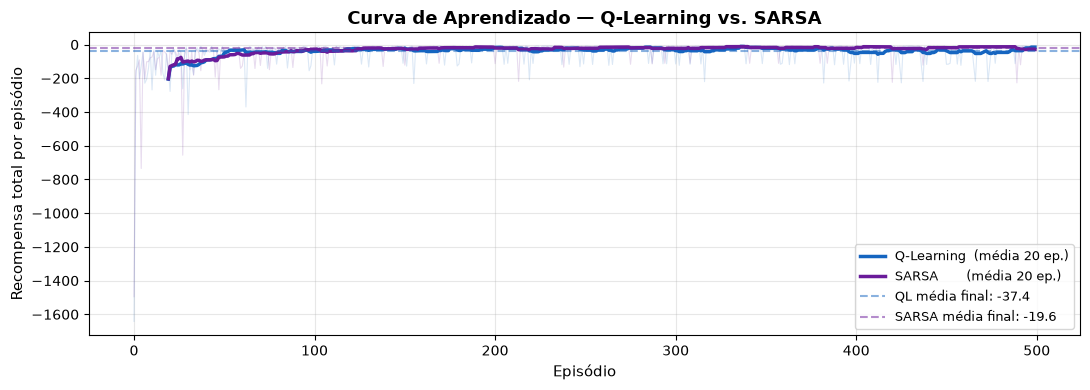


Resumo:
  Q-Learning — recompensa média (últimos 50 ep.):   -37.4
  SARSA      — recompensa média (últimos 50 ep.):   -19.6

  Qual obteve maior recompensa durante o TREINAMENTO? Qual esperaria para EXECUÇÃO?


In [6]:
def media_movel(dados, janela=20):
    return np.convolve(dados, np.ones(janela) / janela, mode='valid')

JANELA = 20
x = range(JANELA - 1, N_EPISODES)

fig, ax = plt.subplots(figsize=(11, 4))

# Curvas brutas (transparentes)
ax.plot(hist_ql,    alpha=0.15, color='#1565C0', linewidth=0.8)
ax.plot(hist_sarsa, alpha=0.15, color='#6A1B9A', linewidth=0.8)

# Médias móveis
ax.plot(x, media_movel(hist_ql,    JANELA), color='#1565C0', linewidth=2.5,
        label=f'Q-Learning  (média {JANELA} ep.)')
ax.plot(x, media_movel(hist_sarsa, JANELA), color='#6A1B9A', linewidth=2.5,
        label=f'SARSA       (média {JANELA} ep.)')

ax.axhline(y=np.mean(hist_ql[-50:]),    color='#1565C0', linestyle='--',
           alpha=0.5, label=f'QL média final: {np.mean(hist_ql[-50:]):.1f}')
ax.axhline(y=np.mean(hist_sarsa[-50:]), color='#6A1B9A', linestyle='--',
           alpha=0.5, label=f'SARSA média final: {np.mean(hist_sarsa[-50:]):.1f}')

ax.set_title('Curva de Aprendizado — Q-Learning vs. SARSA',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Episódio', fontsize=11)
ax.set_ylabel('Recompensa total por episódio', fontsize=11)
ax.legend(fontsize=9, loc='lower right')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\nResumo:")
print(f"  Q-Learning — recompensa média (últimos 50 ep.): {np.mean(hist_ql[-50:]):>7.1f}")
print(f"  SARSA      — recompensa média (últimos 50 ep.): {np.mean(hist_sarsa[-50:]):>7.1f}")
print()
print("  Qual obteve maior recompensa durante o TREINAMENTO? Qual esperaria para EXECUÇÃO?")

---
## Exercício 4 — Política Aprendida e Caminho (avaliação com ε = 0)

Este é o item 3 do "mão na massa" (slide 111): os agentes foram **treinados com ε = 0,1**, mas aqui os **avaliamos com ε = 0** — sem exploração, sempre a melhor ação da Q-table.

A célula abaixo extrai o caminho **greedy** de cada agente, mostra a recompensa desse caminho e desenha a política aprendida.

> Repare: o caminho "seguro" do SARSA não precisa passar pela linha do topo. Com ε = 0,1, ficar a uma linha de distância do penhasco costuma bastar.

Q-Learning: ✅ chegou em 10 passos | recompensa com ε = 0: -9
SARSA     : ✅ chegou em 12 passos | recompensa com ε = 0: -11



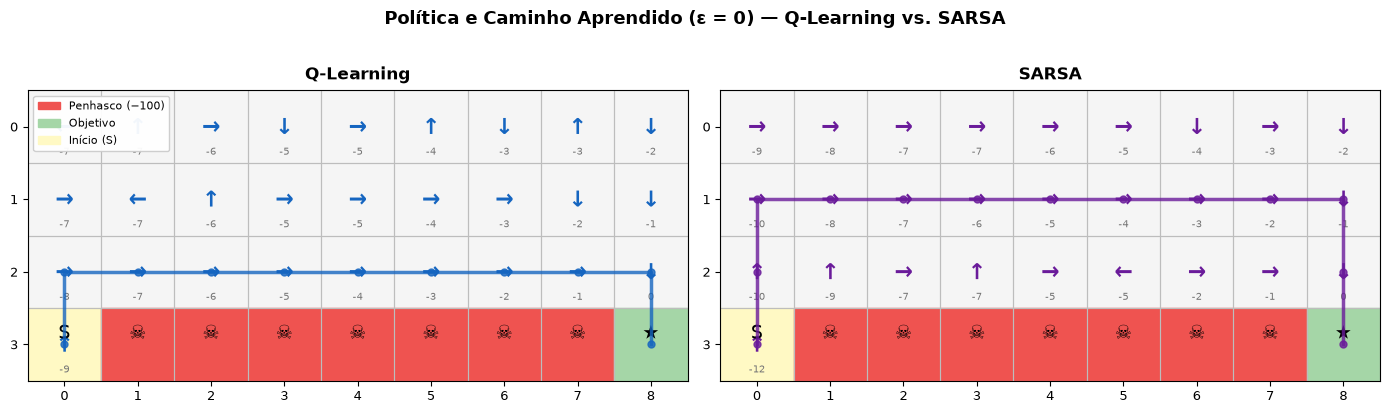

In [7]:
def extrair_caminho(Q, max_steps=100):
    """
    Executa o agente de forma greedy (ε = 0).
    Retorna (caminho percorrido, recompensa total).
    """
    state     = START
    caminho   = [state]
    visitados = {state}
    total     = 0

    for _ in range(max_steps):
        r, c   = state
        action = int(np.argmax(Q[r, c]))
        next_state, reward, done = step(state, action)
        total += reward

        if reward == R_CLIFF:
            print("  [Aviso] Caiu no penhasco seguindo a política greedy — agente não convergiu.")
            break
        if next_state in visitados:
            print("  [Aviso] Loop detectado — agente pode não ter convergido.")
            break

        caminho.append(next_state)
        visitados.add(next_state)
        state = next_state

        if done:
            break

    return caminho, total


path_ql,    rec_ql    = extrair_caminho(Q_ql)
path_sarsa, rec_sarsa = extrair_caminho(Q_sarsa)

for nome, caminho, rec in [('Q-Learning', path_ql, rec_ql), ('SARSA     ', path_sarsa, rec_sarsa)]:
    status = '✅ chegou' if caminho[-1] == GOAL else '❌ não chegou'
    print(f"{nome}: {status} em {len(caminho)-1} passos | recompensa com ε = 0: {rec:+d}")
print()

# Visualiza os dois agentes lado a lado
plot_env(
    Q_ql=Q_ql,       Q_sarsa=Q_sarsa,
    path_ql=path_ql, path_sarsa=path_sarsa,
    title='Política e Caminho Aprendido (ε = 0) — Q-Learning vs. SARSA'
)

### Assista: os dois agentes jogando **com ε = 0,1** (como no treino)

Acima avaliamos com ε = 0. Mas durante o treino os agentes exploravam: em 10% dos passos davam um passo ao acaso. Abaixo, cada agente joga 4 episódios seguidos com a **sua** Q-table e ε = 0,1. O ✖ vermelho marca cada queda no penhasco.

> **Palpite:** qual dos dois vai cair mais? Por quê?

In [8]:
# @title Funções de animação (rode e siga em frente)
from matplotlib import animation
from IPython.display import HTML


def animar(trajetorias, titulos, desenhar_fundo, xy, rotulo, max_quadros=60,
           intervalo=180, largura=3.4, altura=4.2, topo=0.78):
    """Anima as trajetórias lado a lado (uma por painel).

    trajetorias : lista de listas [(estado, recompensa_acumulada, evento), ...]
    Trajetórias longas são aceleradas (pulam passos) para caber em ~max_quadros quadros.
    """
    n = len(trajetorias)
    fig, axes = plt.subplots(1, n, figsize=(largura * n, altura), dpi=60)
    axes = np.atleast_1d(axes)
    pulo = [max(1, -(-len(t) // max_quadros)) for t in trajetorias]
    n_quadros = max(-(-len(t) // p) for t, p in zip(trajetorias, pulo)) + 6   # +6: pausa no fim
    paineis = []
    for ax, traj, tit in zip(axes, trajetorias, titulos):
        desenhar_fundo(ax)
        rastro, = ax.plot([], [], '-', color='#1565C0', alpha=0.35, lw=4, zorder=6)
        quedas, = ax.plot([], [], 'X', color='#B71C1C', ms=14, zorder=7)
        ponto, = ax.plot([], [], 'o', color='#1565C0', ms=13, mec='white', mew=2, zorder=8)
        titulo = ax.set_title(f'{tit}\n{rotulo(traj, 0)}', fontsize=11, fontweight='bold')
        paineis.append((traj, rastro, quedas, ponto, titulo, tit))
    fig.subplots_adjust(left=0.02, right=0.98, bottom=0.02, top=topo, wspace=0.08)

    def quadro(k):
        for (traj, rastro, quedas, ponto, titulo, tit), p in zip(paineis, pulo):
            i = min(k * p, len(traj) - 1)
            # o rastro recomeça a cada episódio novo e depois de cada queda (volta ao início)
            ini = max(j for j in range(i + 1) if j == 0 or traj[j][2] is not None)
            pts = [xy(e) for e, _, _ in traj[ini:i + 1]]
            rastro.set_data([x for x, _ in pts], [y for _, y in pts])
            ponto.set_data([pts[-1][0]], [pts[-1][1]])
            qx = [xy(ev[1]) for _, _, ev in traj[:i + 1] if isinstance(ev, tuple)]
            quedas.set_data([x for x, _ in qx], [y for _, y in qx])
            titulo.set_text(f'{tit}\n{rotulo(traj, i)}')
        return []

    anim = animation.FuncAnimation(fig, quadro, frames=n_quadros, interval=intervalo)
    plt.close(fig)
    return HTML(anim.to_jshtml(default_mode='once'))


def rodar_episodios(Q, epsilon, n_episodios=4, seed=0, max_passos=200):
    """Joga episódios seguidos com ε-greedy. Marca o início de cada episódio ('novo') e
    as quedas no penhasco (evento = ('queda', célula onde caiu))."""
    rng = random.Random(seed)
    traj = []
    for ep in range(n_episodios):
        estado, total = START, 0
        traj.append((estado, 0, 'novo'))
        for _ in range(max_passos):
            a = rng.choice(ACTIONS) if rng.random() < epsilon else int(np.argmax(Q[estado]))
            dr, dc = ACTION_DELTAS[a]
            alvo = (int(np.clip(estado[0] + dr, 0, ROWS - 1)), int(np.clip(estado[1] + dc, 0, COLS - 1)))
            estado, r, done = step(estado, a)
            total += r
            traj.append((estado, total, ('queda', alvo) if r == R_CLIFF else None))
            if done:
                break
    return traj


def _fundo_penhasco(ax):
    for r in range(ROWS):
        for c in range(COLS):
            pos = (r, c)
            cor = '#EF5350' if pos in CLIFF else '#FFF9C4' if pos == START else '#A5D6A7' if pos == GOAL else '#F5F5F5'
            ax.add_patch(plt.Rectangle((c, ROWS - r - 1), 1, 1, facecolor=cor, edgecolor='#BDBDBD', lw=0.8))
            icone = '☠' if pos in CLIFF else 'S' if pos == START else '★' if pos == GOAL else ''
            if icone:
                ax.text(c + 0.5, ROWS - r - 0.5, icone, ha='center', va='center', fontsize=13, alpha=0.6)
    ax.set_xlim(0, COLS); ax.set_ylim(0, ROWS); ax.set_aspect('equal'); ax.axis('off')


def _rotulo_penhasco(traj, i):
    ep = sum(1 for e in traj[:i + 1] if e[2] == 'novo')
    n_ep = sum(1 for e in traj if e[2] == 'novo')
    quedas = sum(1 for e in traj[:i + 1] if isinstance(e[2], tuple))
    return f'episódio {ep}/{n_ep} | quedas: {quedas}\nrecompensa do episódio: {traj[i][1]:+d}'


def animar_penhasco(trajetorias, titulos):
    return animar(trajetorias, titulos, _fundo_penhasco,
                  xy=lambda e: (e[1] + 0.5, ROWS - e[0] - 0.5), rotulo=_rotulo_penhasco,
                  max_quadros=90, intervalo=150, largura=6.0, altura=3.8, topo=0.74)

In [9]:
# Mesma sequência de sorteios para os dois agentes. Troque a semente e rode de novo: em algumas
# o Q-Learning não cai, e às vezes até o SARSA cai. Por isso a célula seguinte mede 1000 episódios.
SEMENTE = 12
trajetorias = [rodar_episodios(Q_ql, 0.1, seed=SEMENTE), rodar_episodios(Q_sarsa, 0.1, seed=SEMENTE)]
animar_penhasco(trajetorias, ['Q-Learning (ε = 0,1)', 'SARSA (ε = 0,1)'])

In [10]:
# Uma animação é só um exemplo. Para concluir algo, medimos em muitos episódios (slide 135).
def estatisticas(Q, epsilon=0.1, n=1000):
    quedas, recompensa = 0, 0
    for k in range(n):
        traj = rodar_episodios(Q, epsilon, n_episodios=1, seed=10_000 + k)
        quedas += sum(isinstance(ev, tuple) for _, _, ev in traj)
        recompensa += traj[-1][1]
    return quedas / n, recompensa / n

for nome, Q_ in [('Q-Learning', Q_ql), ('SARSA     ', Q_sarsa)]:
    q, r = estatisticas(Q_)
    print(f'{nome}: {q:.2f} quedas por episódio | recompensa média {r:7.1f}   (1000 episódios, ε = 0,1)')

Q-Learning: 0.23 quedas por episódio | recompensa média   -36.9   (1000 episódios, ε = 0,1)


SARSA     : 0.06 quedas por episódio | recompensa média   -19.1   (1000 episódios, ε = 0,1)


**Para pensar** (anote antes de ir para o Exercício 5)
1. Com ε = 0 o Q-Learning fez o caminho mais curto. Por que, com ε = 0,1, ele perde para o SARSA?
2. O SARSA "sabe" que vai explorar? Em que linha do código essa informação entra na Q-table?
3. Num robô de verdade andando perto de uma escada, qual dos dois você usaria durante o aprendizado? E depois, já treinado e sem explorar?

<details><summary>Respostas (clique para abrir)</summary>

1. O Q-Learning aprende o valor da política **ótima sem exploração** (usa o `max`). O caminho ótimo passa colado no penhasco; com ε = 0,1, um passo ao acaso para baixo derruba o agente (−100). A política é ótima, mas quem anda por ela explorando cai.
2. Sim: o alvo do SARSA usa `Q[nr, nc, next_action]`, e `next_action` foi sorteada com o ε-greedy. As quedas causadas pela exploração entram no valor das células da borda, que ficam ruins — por isso o SARSA se afasta.
3. Durante o aprendizado (explorando de verdade), SARSA: aprende um caminho que é seguro **para quem explora**. Depois de treinado e sem exploração, o caminho do Q-Learning é mais curto — desde que a execução seja de fato sem erros.
</details>

---
## Exercício 5 — Impacto de ε na Diferença entre os Algoritmos (➕ opcional)

O valor de **ε** é a peça-chave para entender **por que SARSA e Q-Learning se comportam diferente** neste ambiente.

- Quando **ε = 0** (sem exploração), os dois algoritmos convergem para a **mesma política** (o caminho mais curto).
- Quando **ε > 0**, o SARSA *sabe* que cometerá erros aleatórios e aprende a se afastar do penhasco.  
  O Q-Learning ignora isso — planeja para o melhor caso e sofre as consequências durante a exploração.

Execute a célula abaixo para comparar os dois algoritmos **treinados** com três valores de ε (a recompensa mostrada é a do treino, com exploração).

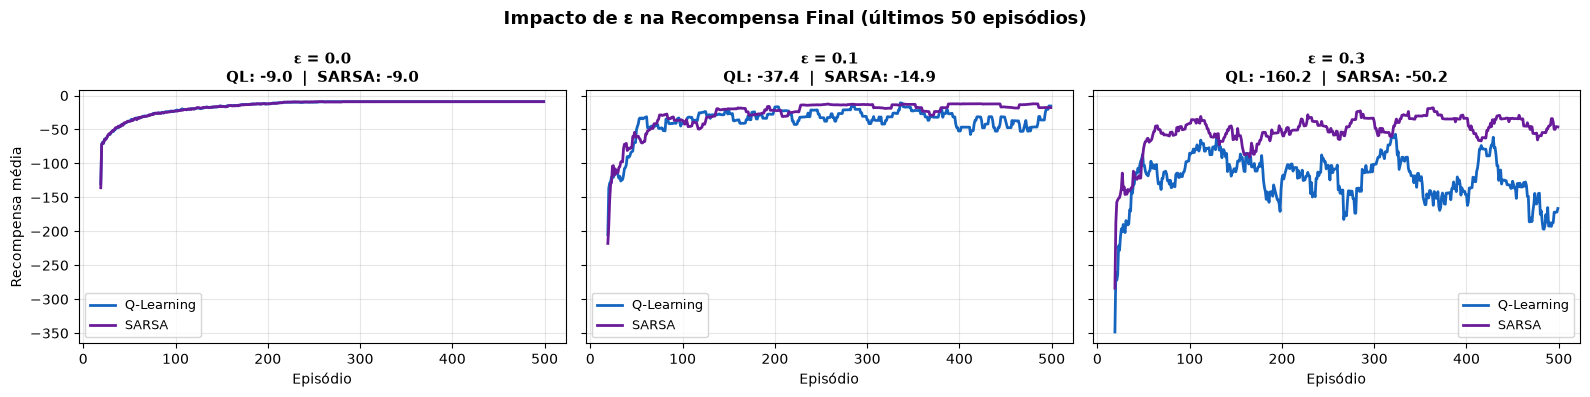

In [11]:
epsilons_teste = [0.0, 0.1, 0.3]

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
fig.suptitle('Impacto de ε na Recompensa Final (últimos 50 episódios)',
             fontsize=13, fontweight='bold')

for ax, eps in zip(axes, epsilons_teste):
    np.random.seed(SEED); random.seed(SEED)
    _, h_ql = treinar_qlearning(ALPHA, GAMMA, eps, N_EPISODES)

    np.random.seed(SEED); random.seed(SEED)
    _, h_sa = treinar_sarsa(ALPHA, GAMMA, eps, N_EPISODES)

    x = range(JANELA - 1, N_EPISODES)
    ax.plot(x, media_movel(h_ql, JANELA), color='#1565C0', linewidth=2, label='Q-Learning')
    ax.plot(x, media_movel(h_sa, JANELA), color='#6A1B9A', linewidth=2, label='SARSA')

    media_ql = np.mean(h_ql[-50:])
    media_sa = np.mean(h_sa[-50:])

    ax.set_title(f'ε = {eps}\nQL: {media_ql:.1f}  |  SARSA: {media_sa:.1f}',
                 fontsize=11, fontweight='bold')
    ax.set_xlabel('Episódio', fontsize=10)
    ax.legend(fontsize=9)
    ax.grid(alpha=0.3)

axes[0].set_ylabel('Recompensa média', fontsize=10)
plt.tight_layout()
plt.show()

---
## Experimento extra — Pergunta 5 (desafio)

Treinamos os dois agentes **com ε = 0,1** e, depois, simulamos os dois **com ε = 0**. Para não depender de uma única execução (slide 135), repetimos com 5 sementes.

In [12]:
print(f"{'semente':>7s} | {'QL passos':>9s} {'QL rec.':>8s} | {'SARSA passos':>12s} {'SARSA rec.':>10s}")
for semente in range(5):
    np.random.seed(semente); random.seed(semente)
    Q_a, _ = treinar_qlearning(ALPHA, GAMMA, 0.1, N_EPISODES)
    np.random.seed(semente); random.seed(semente)
    Q_b, _ = treinar_sarsa(ALPHA, GAMMA, 0.1, N_EPISODES)
    p_a, r_a = extrair_caminho(Q_a)
    p_b, r_b = extrair_caminho(Q_b)
    print(f'{semente:7d} | {len(p_a)-1:9d} {r_a:+8d} | {len(p_b)-1:12d} {r_b:+10d}')

semente | QL passos  QL rec. | SARSA passos SARSA rec.


      0 |        10       -9 |           12        -11


      1 |        10       -9 |           12        -11


      2 |        10       -9 |           12        -11


      3 |        10       -9 |           12        -11


      4 |        10       -9 |           12        -11


---
## Perguntas de Reflexão

Responda às perguntas abaixo na célula de texto seguinte. Use os gráficos e resultados obtidos para embasar suas respostas.

---

**1.** Observe o gráfico do Exercício 3. Durante o treinamento (com ε > 0), qual algoritmo obteve maior recompensa média — Q-Learning ou SARSA? Por quê? Isso é esperado pela teoria?

**2.** Observe o Exercício 4. O caminho do Q-Learning e do SARSA são iguais ou diferentes? Explique, em termos das equações de atualização, por que isso acontece neste ambiente específico.

**3.** Observe o Exercício 5. O que acontece com a diferença entre Q-Learning e SARSA à medida que ε se aproxima de zero? Que conclusão você tira sobre a relação entre ε e o comportamento on-policy vs. off-policy?

**4.** Em qual cenário de negócios você preferiria usar SARSA em vez de Q-Learning? Justifique com base no conceito de on-policy vs. off-policy e no trade-off entre exploração e segurança.

**5. (Desafio)** O Q-Learning é chamado de **off-policy** porque aprende a política ótima independente do que o agente executa. Se você remover completamente a exploração (ε = 0) após o treinamento e simular os dois agentes, os resultados convergem? Execute um experimento e explique o resultado.

### Respostas (gabarito)

Os números abaixo vêm da execução deste notebook. Em outra execução eles variam um pouco, mas as conclusões se mantêm.

**Questão 1:**
Durante o treino com ε = 0,1, o **SARSA** teve recompensa média maior (Exercício 3: cerca de −20 contra −37 do Q-Learning). Isso é o esperado pela teoria (slide 108): o Q-Learning aprende o caminho pela borda do penhasco e, como continua explorando 10% das vezes, um passo aleatório para baixo o derruba (−100). O SARSA incorpora essa exploração no alvo e aprende a andar afastado da borda, caindo bem menos.

**Questão 2:**
São **diferentes**. O Q-Learning anda pela linha logo acima do penhasco (10 passos, recompensa −9); o SARSA sobe mais uma linha (12 passos, recompensa −11).
- O alvo do Q-Learning usa `max Q(s', a')`: ele avalia cada casa supondo que dali em diante agirá de forma ótima, então a borda parece segura.
- O alvo do SARSA usa `Q(s', a')` da ação ε-greedy que será executada de fato: as casas da borda carregam o risco de um passo aleatório para baixo e ficam com valor menor.

**Questão 3:**
Com **ε = 0** os dois ficam idênticos (−9 e −9): se a próxima ação é sempre a gulosa, `Q(s', a') = max Q(s', a')` e as duas regras de atualização coincidem. Conforme ε cresce, a diferença aumenta (ε = 0,1: −37 contra −15; ε = 0,3: −160 contra −50).
Conclusão: a diferença entre on-policy e off-policy só aparece porque há exploração. O SARSA aprende o valor da política que realmente executa (com os erros dela); o Q-Learning aprende o valor da política ótima, mesmo executando outra.

> Curiosidade: mesmo com ε = 0 o agente ainda explora no começo. A Q-table começa em 0 e todas as recompensas são negativas, então qualquer ação ainda não testada parece melhor que as já testadas (inicialização otimista).

**Questão 4:**
O SARSA é preferível quando o agente **continua explorando enquanto opera** e cada erro custa caro: robôs físicos, operações financeiras ao vivo, ajuste de dose em saúde, preço dinâmico em produção. Ele troca um pouco de desempenho ótimo por segurança durante o aprendizado (slide 109).
O Q-Learning faz sentido quando a exploração acontece num simulador, sem custo real, e o agente vai para produção com ε = 0.

**Questão 5 (Desafio):**
**Não convergem.** No experimento extra, nas 5 sementes, o Q-Learning greedy faz o caminho ótimo (10 passos, −9) e o SARSA greedy faz o caminho seguro (12 passos, −11).
Zerar o ε depois do treino não muda a Q-table: o SARSA aprendeu os valores da política ε-greedy, que penalizam a borda, então a política gulosa extraída dessa tabela continua evitando a borda. Para o SARSA também chegar ao caminho ótimo, o ε precisaria decair até 0 **durante** o treino.

---
## Resumo — O que você praticou neste exercício

| Habilidade | O que foi exercitado |
|---|---|
| Implementação | Equação de Bellman para Q-Learning e SARSA |
| Conceito central | Diferença on-policy vs. off-policy |
| Análise crítica | Leitura e interpretação de curvas de aprendizado |
| Pensamento aplicado | Trade-off entre risco e otimidade em negócios |
| Experimentação | Impacto de hiperparâmetros (ε) no comportamento dos agentes |

### Próximo passo natural

A Q-table funciona bem para espaços de estados discretos e pequenos.  
Quando o espaço de estados explode (pixels de vídeo, variáveis contínuas), a solução é substituir a tabela por uma **rede neural** — esse é o **Deep Q-Network (DQN)**, base dos agentes que jogam Atari e jogos complexos.